# UCS420 Lab Assignment 9 — NLP Text Preprocessing


In [ ]:
ROLL_NO = 1024160093         # <-- your full roll number
NAME = "Zaira Iqbal"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160093   Name: Zaira Iqbal   Fingerprint: CF68BE2A   Tickets: 15

Ticket_ID                                                                            Ticket_Text
      T01    Lms keeps asking for login while uploading the file. The same problem occurs again.
      T02                                            I can't login and I didn't change anything.
      T03                                 VPN is running slowly on my laptop. Please resolve it.
      T04                      Password is not working after resetting my password. Please help.
      T05    Lms has stopped syncing after resetting my password. The same problem occurs again.
      T06                                      The projector failed to open. Can you check this?
      T07 Printer crashes while opening after resetting my password. I have tried several times!
      T08                                            The state-of-the-art lab (Lab-3) is closed.
      T09                              The p

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:
import pandas as pd
from nltk.stem import PorterStemmer, LancasterStemmer
from nltk.stem import RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet

porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()

# RegexpStemmer removes common suffixes.
# We will inspect its results to identify possible over-stemming.
regexp_stemmer = RegexpStemmer(
    r"(ing|edly|ed|ly|es|s)$",
    min=4
)

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    elif tag.startswith("V"):
        return wordnet.VERB
    elif tag.startswith("N"):
        return wordnet.NOUN
    elif tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

# Obtain unique final tokens using the official pipeline.
q4_tokens = sorted({
    token
    for _, row in df.iterrows()
    for token in process_ticket(row["Ticket_Text"])["final"]
})

# POS-tag the tokens.
tagged_words = pos_tag(q4_tokens)

comparison = []

for word, tag in tagged_words:
    pos = get_wordnet_pos(tag)

    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regexp_result = regexp_stemmer.stem(word)
    lemma_result = lemmatizer.lemmatize(word, pos=pos)

    outputs = [
        porter_result,
        lancaster_result,
        regexp_result,
        lemma_result
    ]

    if len(set(outputs)) > 1:
        comparison.append({
            "Word": word,
            "POS tag": tag,
            "Porter Stem": porter_result,
            "Lancaster Stem": lancaster_result,
            "Regexp Stem": regexp_result,
            "WordNet Lemma": lemma_result
        })

q4_table = pd.DataFrame(comparison)

print("Number of unique final tokens:", len(q4_tokens))
print("Words with differing outputs:", len(q4_table))
display(q4_table)


Number of unique final tokens: 59
Words with differing outputs: 33


,Word,POS tag,Porter Stem,Lancaster Stem,Regexp Stem,WordNet Lemma
0,access,NN,access,access,acces,access
1,another,DT,anoth,anoth,another,another
2,anything,NN,anyth,anyth,anyth,anything
3,call,VB,call,cal,call,call
4,change,NN,chang,chang,change,change
5,closed,VBD,close,clos,clos,close
6,code,NN,code,cod,code,code
7,computer,NN,comput,comput,computer,computer
8,error,NN,error,er,error,error
9,file,NN,file,fil,file,file


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* Some final tokens, such as `n't`, `'s`, and `ca`, are not complete words. They come from contractions such as `isn't`, `user's`, and `can't`. The tokenizer splits contractions into smaller parts, and these fragments may remain after preprocessing and stopword removal.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]


patterns = {
    "Long words": r"\b[A-Za-z]{6,}\b",
    "Numbers": r"\b\d+(?:\.\d+)*\b",
    "Capitalized words": r"\b[A-Z][a-zA-Z]*\b",
    "Vowel-starting words": r"\b[aeiouAEIOU][a-zA-Z]*\b"
}

for i, line in enumerate(TEST_LINES, 1):
    print(f"\nLine {i}")
    for label, pattern in patterns.items():
        print(label, re.findall(pattern, line))

def redact(text):
    text = re.sub(r"\b[A-Z0-9._%+-]+@[A-Z0-9.-]+\.[A-Z]{2,}\b", "<EMAIL>", text, flags=re.I)
    text = re.sub(r"https?://[^\s]+|www\.[^\s]+", "<URL>", text, flags=re.I)
    text = re.sub(r"(?<!\w)(?:\+?\d[\d\s().-]{7,}\d)(?!\w)", "<PHONE>", text)
    return text

for line in TEST_LINES:
    print(redact(line))



Line 1
Long words ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers []
Capitalized words ['Mail']
Vowel-starting words ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']

Line 2
Long words ['Version']
Numbers ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250']
Capitalized words ['Call', 'Version', 'Rs']
Vowel-starting words ['or', 'is']

Line 3
Long words []
Numbers ['5.30']
Capitalized words ['The']
Vowel-starting words ['of', 'art', 'isn', 'open', 'in', 'at']
Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>
Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* Some words are capitalized only because they occur at the beginning of a sentence, rather than because they are proper nouns. The exact count depends on the generated tickets and must be obtained by checking your extracted capitalized words.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:

pattern = (
    r"https?://[^\s]+|www\.[^\s]+|"
    r"[A-Z0-9._%+-]+@[A-Z0-9.-]+\.[A-Z]{2,}|"
    r"\+?\d[\d(). -]{7,}\d|"
    r"\d+(?:\.\d+)+|"
    r"[A-Za-z]+(?:[-'][A-Za-z]+)+|"
    r"[A-Za-z]+|\d+|[^\w\s]"
)

tokenizer = RegexpTokenizer(pattern, flags=re.IGNORECASE)

def my_tokenize(text):
    return tokenizer.tokenize(str(text))

for line in TEST_LINES:
    print("\nText:", line)
    print("Custom:", my_tokenize(line))
    print("NLTK:", word_tokenize(line))



Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
NLTK: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
NLTK: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Custom: ['The', 'state-of-the-art'

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* The exact number depends on the generated tickets. The custom tokenizer preserves contractions, hyphenated words, decimals, version numbers, email addresses, URLs, and phone numbers as single tokens, whereas word_tokenize() may split some of them into multiple tokens.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
results = []
for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])
    results.append(result)

rows = []
for i, result in enumerate(results):
    rows.append({
        "Ticket_ID": df.iloc[i]["Ticket_ID"],
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique tokens": len(set(result["tokens"])),
        "Final tokens": len(result["final"])
    })

q1_table = pd.DataFrame(rows)

total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": q1_table["Sentences"].sum(),
    "Tokens": q1_table["Tokens"].sum(),
    "Punctuation tokens": q1_table["Punctuation tokens"].sum(),
    "Stopwords": q1_table["Stopwords"].sum(),
    "Unique tokens": len(set(
        token
        for result in results
        for token in result["tokens"]
    )),
    "Final tokens": q1_table["Final tokens"].sum()
}

q1_table = pd.concat(
    [q1_table, pd.DataFrame([total_row])],
    ignore_index=True
)

display(q1_table)

# Display the actual processing output for the two focus tickets
print("Focus ticket IDs:", FOCUS)

for ticket_id in FOCUS:
    idx = df.index[df["Ticket_ID"] == ticket_id][0]
    print("\nTicket ID:", ticket_id)
    print("Raw text:", df.loc[idx, "Ticket_Text"])
    print("Sentences:", results[idx]["sentences"])
    print("Tokens:", results[idx]["tokens"])
    print("Punctuation:", results[idx]["punct"])
    print("Stopwords:", results[idx]["stops"])
    print("Final tokens:", results[idx]["final"])


,Ticket_ID,Sentences,Tokens,Punctuation tokens,Stopwords,Unique tokens,Final tokens
0,T01,2,16,2,6,14,8
1,T02,1,11,1,4,9,6
2,T03,2,12,2,4,11,6
3,T04,2,12,2,4,10,6
4,T05,2,15,2,6,14,7
5,T06,2,11,2,5,11,4
6,T07,2,15,2,5,15,8
7,T08,1,9,3,2,9,4
8,T09,2,11,2,4,10,5
9,T10,2,13,2,3,12,8


Focus ticket IDs: ['T02', 'T13']

Ticket ID: T02
Raw text: I can't login and I didn't change anything.
Sentences: ["I can't login and I didn't change anything."]
Tokens: ['i', 'ca', "n't", 'login', 'and', 'i', 'did', "n't", 'change', 'anything', '.']
Punctuation: ['.']
Stopwords: ['i', 'and', 'i', 'did']
Final tokens: ['ca', "n't", 'login', "n't", 'change', 'anything']

Ticket ID: T13
Raw text: I cannot access the password after the latest update. Is there another solution?
Sentences: ['I cannot access the password after the latest update.', 'Is there another solution?']
Tokens: ['i', 'can', 'not', 'access', 'the', 'password', 'after', 'the', 'latest', 'update', '.', 'is', 'there', 'another', 'solution', '?']
Punctuation: ['.', '?']
Stopwords: ['i', 'can', 'not', 'the', 'after', 'the', 'is', 'there']
Final tokens: ['access', 'password', 'latest', 'update', 'another', 'solution']


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* Over-stemming occurs when a stemmer removes too much of a word, potentially changing its meaning. Under-stemming occurs when related words are not reduced to the same stem. Examples should be selected from the actual comparison table generated from my dataset.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total Tokens,Unique Tokens,TTR
0,S1,186,90,0.4839
1,S2,158,85,0.5380
2,S3,92,59,0.6413
3,S4,92,57,0.6196


Top 10 words of S1:
[('.', 21), ('the', 9), ('password', 7), ('i', 6), ('is', 6), ('my', 6), ('after', 6), ('resetting', 5), ('lms', 3), ('login', 3)]

Top 10 words of S3:
[('password', 7), ('resetting', 5), ('lms', 3), ('login', 3), ('please', 3), ('another', 3), ('keeps', 2), ('asking', 2), ('problem', 2), ('occurs', 2)]

Top 5 bigrams of S1:
[(('after', 'resetting'), 5), (('resetting', 'my'), 5), (('my', 'password'), 5), (('password', '.'), 5), (('.', 'the'), 4)]

Top 5 bigrams of S3:
[(('resetting', 'password'), 5), (('lms', 'keeps'), 2), (('keeps', 'asking'), 2), (('asking', 'login'), 2), (('problem', 'occurs'), 2)]


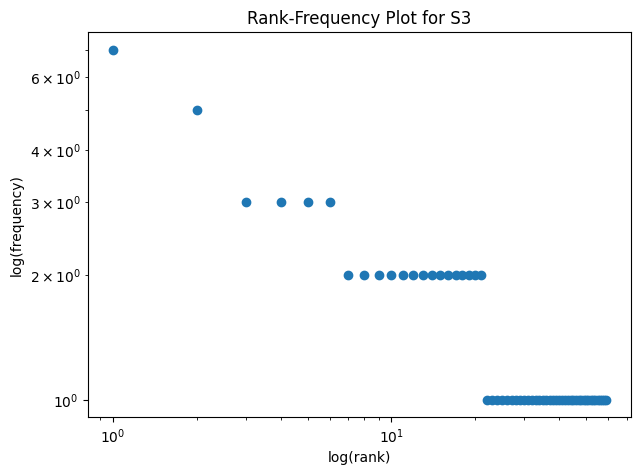

In [ ]:

import re
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from nltk.stem import PorterStemmer

porter = PorterStemmer()

S1 = []
S2 = []
S3 = []

for _, row in df.iterrows():
    text = str(row["Ticket_Text"])
    result = process_ticket(text)

    tokens = result["tokens"]
    final = result["final"]

    S1.extend(tokens)
    S2.extend([t for t in tokens if not re.fullmatch(r"[^\w\s]", t)])
    S3.extend(final)

S4 = [porter.stem(str(t)) for t in S3]

corpora = {"S1": S1, "S2": S2, "S3": S3, "S4": S4}

stats = []
for name, tokens in corpora.items():
    stats.append({
        "Corpus": name,
        "Total Tokens": len(tokens),
        "Unique Tokens": len(set(tokens)),
        "TTR": round(len(set(tokens)) / len(tokens), 4) if tokens else 0
    })

display(pd.DataFrame(stats))

print("Top 10 words of S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words of S3:")
print(Counter(S3).most_common(10))

def get_bigrams(tokens):
    return Counter(zip(tokens, tokens[1:])).most_common(5)

print("\nTop 5 bigrams of S1:")
print(get_bigrams(S1))

print("\nTop 5 bigrams of S3:")
print(get_bigrams(S3))

frequencies = sorted(Counter(S3).values(), reverse=True)
ranks = range(1, len(frequencies) + 1)

plt.figure(figsize=(7, 5))
plt.plot(ranks, frequencies, marker="o", linestyle="none")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Rank-Frequency Plot for S3")
plt.show()



**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR (Type-Token Ratio) is the ratio of unique tokens to total tokens. It changes because preprocessing and stemming alter the token collection. Porter stemming combines different forms of words into common stems, often reducing the number of unique tokens. The exact change depends on the dataset.

Q6. Interpretation

**(a)** **Why does TTR change from S1 to S4?**
TTR changes because stemming combines different word forms into common stems, changing the number of unique tokens relative to the total tokens.

**(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.**
For example, state-of-the-art may be kept as one token by my custom tokenizer, whereas word_tokenize() can split it into multiple tokens. This happens because my regular expression explicitly preserves hyphenated words.

**(c) Give one example where stemming produces an undesirable result.**
Stemming can remove meaningful suffixes and produce a word fragment that is not a valid word. An actual example should be taken from my stemming comparison table.

**(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.**
POS-aware lemmatization uses grammatical information to identify a word's base form. For example, the verb running can be lemmatized to run, while a stemmer may produce a shortened form that is not a valid word.